# Predicción de churn en un banco

Métodos y Aplicaciones de Analítica II, Pontificia Universidad Javeriana

**Presentado por:**

- María José Jiménez
- Ana Sofía Carranza

## Configuración

In [1]:
# Agrego la carpeta anterior a la ruta para poder importar src
import sys
sys.path.insert(0, "..")
%load_ext autoreload
%autoreload 2

from src import evaluation as ev, utils, flujo as fl, modelo_keras as mk
from src.datos import data_prep as dp, eda
from src.modelos import svm_model as svm, ensemble_models as ens, regresion_logistica as rl

Los pasos lentos (búsquedas, entrenamientos finales y cálculos de importancia) se guardan en `models/cache/` la primera vez. Las siguientes veces se cargan en segundos.

- Si cambian los datos o el código de los modelos, hay que ejecutar `utils.borrar_cache()` y volver a correr todo una vez.


## Carga y limpieza de los datos

In [2]:
# Cargo los datos, los limpio y reviso las variables
df = fl.cargar_datos()
eda.resumen_general(df)

Registros duplicados eliminados: 0
(10127, 18)


,tipo,nulos,unicos
customer_age,int64,0,45
gender,string,0,2
dependent_count,int64,0,6
education_level,string,0,7
marital_status,string,0,4
income_category,string,0,6
card_category,string,0,4
months_on_book,int64,0,44
total_relationship_count,int64,0,6
months_inactive_12_mon,int64,0,7


### Análisis: resumen de las variables

- La base tiene 10.127 registros y 18 variables (una es churn, la variable objetivo). No hay IDs repetidos.
- No hay valores nulos en ninguna variable.
- Cinco variables son de texto (género, educación, estado civil, ingreso y tarjeta) y el resto son números.
- Los valores "Unknown" no cuentan como nulos, pero son datos faltantes. Se revisan en la tabla de abajo.

## Partición de los datos para los modelos

In [3]:
# Separo los datos en entrenamiento y prueba
datos = fl.particionar(df)

(8101, 17) (2026, 17)


## Balance de clases y datos Unknown

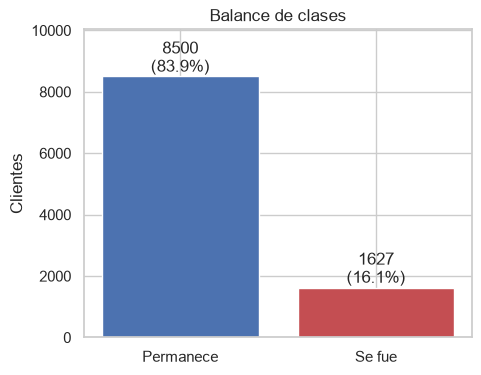

,variable,n_unknown,pct_unknown,churn_unknown_%,churn_resto_%
0,education_level,1519,15.0,16.9,15.9
1,marital_status,749,7.4,17.2,16.0
2,income_category,1112,11.0,16.8,16.0


In [4]:
# Reviso el balance de clases y cuántos Unknown hay
eda.plot_balance_clases(df)
eda.tabla_unknown(df)

### Análisis: balance de clases y datos Unknown

- **Balance:** 8.500 clientes permanecen (83,9%) y 1.627 se fueron (16,1%). Las clases están desbalanceadas.
- Por eso la exactitud (accuracy) sola no sirve. Se usan recall, F1 y PR-AUC, y se ajusta el umbral de decisión.
- **Unknown:** educación tiene 1.519 registros (15,0%), ingreso 1.112 (11,0%) y estado civil 749 (7,4%).
- Su churn (17%) es casi igual al del resto (16%). Por eso se dejan como categoría propia y no se eliminan registros.

## Variables continuas por churn

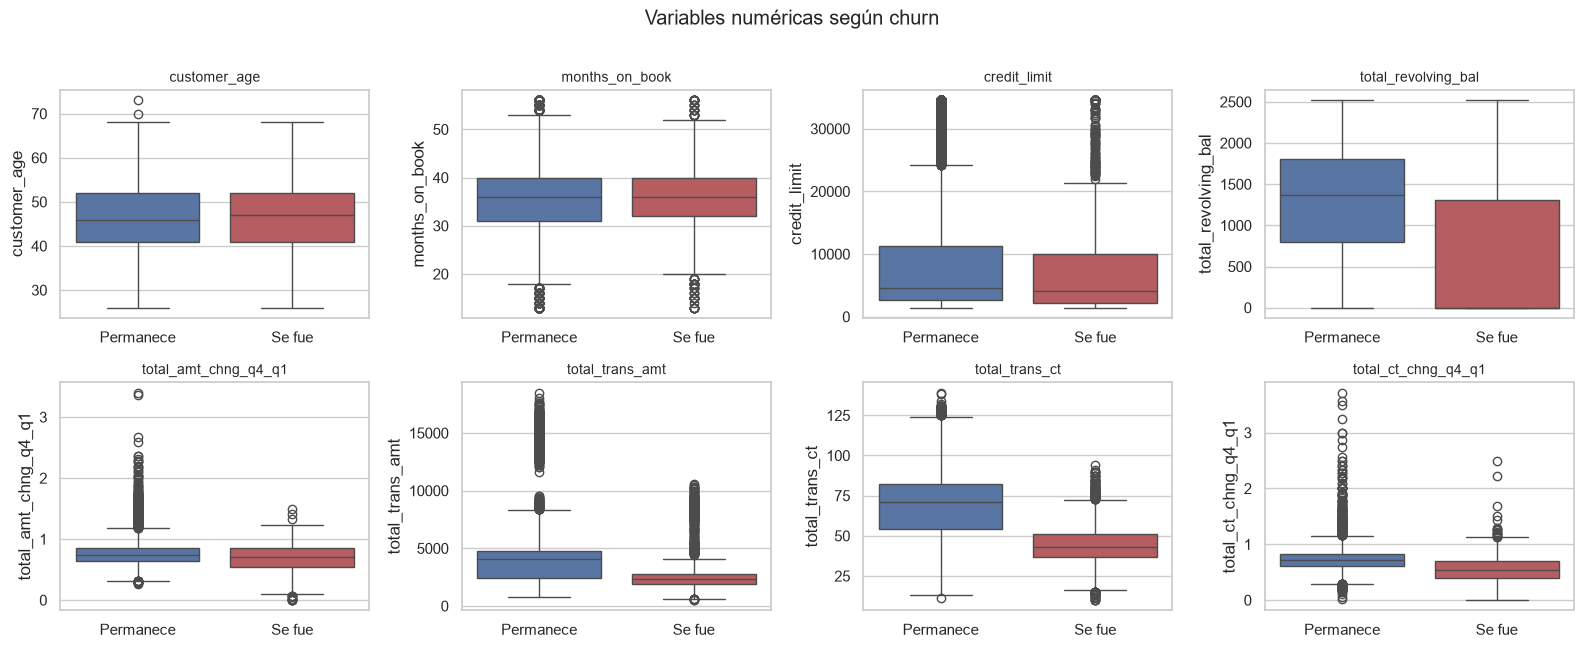

total_trans_ct             -0.371
total_ct_chng_q4_q1        -0.290
total_revolving_bal        -0.263
contacts_count_12_mon       0.204
total_trans_amt            -0.169
months_inactive_12_mon      0.152
total_relationship_count   -0.150
total_amt_chng_q4_q1       -0.131
credit_limit               -0.024
dependent_count             0.019
customer_age                0.018
months_on_book              0.014
Name: churn, dtype: float64

In [5]:
# Dejo solo las variables continuas, porque las de pocos valores van en el gráfico de churn por valor
eda.plot_numericas_por_churn(df)
eda.correlacion_con_target(df)

### Análisis: variables numéricas y correlación con churn

- **Actividad:** quienes se fueron hacen menos transacciones (mediana 43 contra 71) y su monto total también es menor (mediana 2.329 contra 4.100).
- **Saldo:** la mediana del saldo rotativo es 0 en quienes se fueron y 1.364 en quienes se quedaron. El 55% de los que se fueron tiene saldo 0, contra 19% de los que se quedaron.
- **Cambio de actividad (Q4 contra Q1):** la mediana de total_ct_chng_q4_q1 es 0,53 en quienes se fueron y 0,72 en quienes se quedaron. Los que se fueron ya venían bajando su uso.
- **Sin diferencia:** edad, meses en el banco y cupo son casi iguales en los dos grupos.
- **Correlación:** la tabla confirma el orden. total_trans_ct (-0,37), total_ct_chng_q4_q1 (-0,29) y total_revolving_bal (-0,26) son las más fuertes.

Para el banco: el cliente que usa menos su producto y baja su saldo es el que más probablemente se va.

## Churn por cada valor y distribución de transacciones

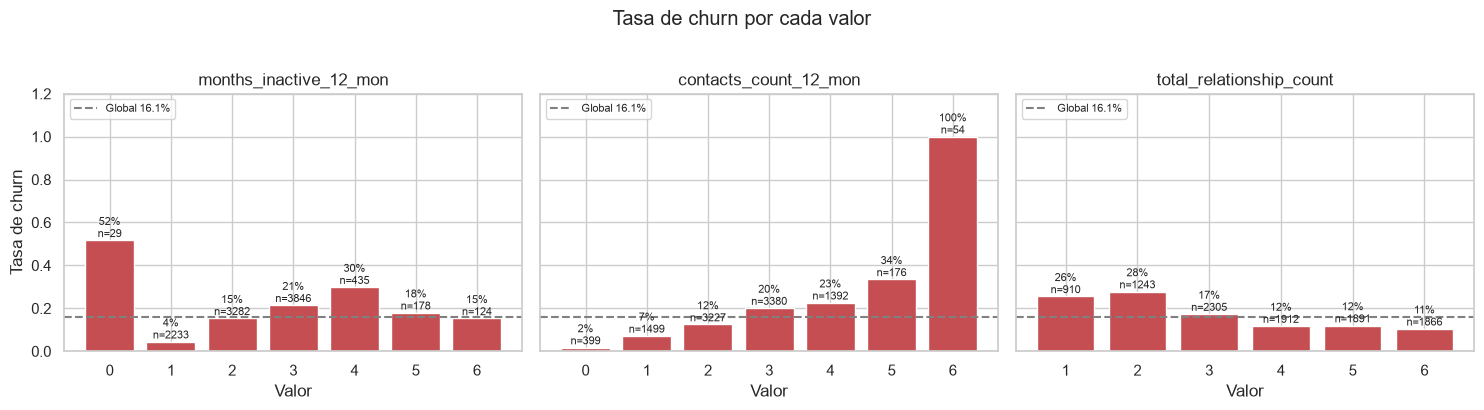

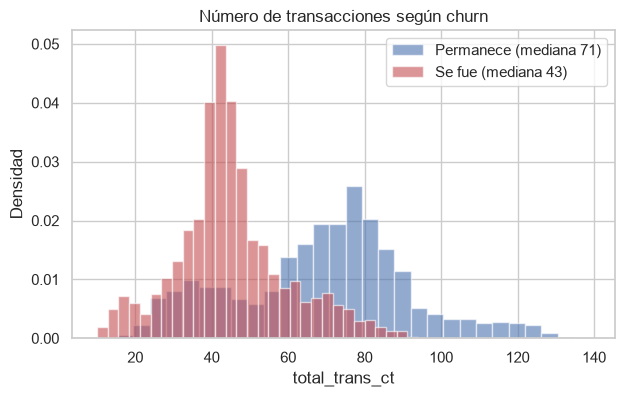

In [6]:
# Miro el churn por cada valor y cómo se distribuyen las transacciones
eda.plot_churn_por_valor(df)
eda.plot_distribucion_transacciones(df)

### Análisis: churn por cada valor y transacciones

Qué muestran los gráficos:

- **Meses inactivo:** con 1 mes el churn es de 4%, y sube a 30% con 4 meses. Quien deja de usar el producto varios meses se va más. Con 0 meses el churn es 52%, pero son solo 29 clientes, así que no es una cifra confiable.
- **Contactos con el banco:** a más contactos en 12 meses, más churn. Es 2% con 0 contactos y 34% con 5. Con 6 contactos se fueron todos, pero son solo 54 clientes.
- **Productos con el banco:** con 1 o 2 productos el churn es de 26% a 28%, y con 6 productos baja a 11%. Más productos significa más vínculo con el banco.
- **Transacciones:** los clientes que se fueron hacen menos. La mediana es 43, contra 71 de los que se quedaron. El 73% de los que se fueron hizo 50 transacciones o menos, contra 23% de los que se quedaron.

Para el banco:

- Los beneficios deberían priorizar a clientes con pocas transacciones, 3 o más meses sin actividad y muchos contactos.
- Los clientes con 1 o 2 productos son un buen grupo para ofrecer más productos y así aumentar el vínculo.

## Churn por categoría y matriz de correlación

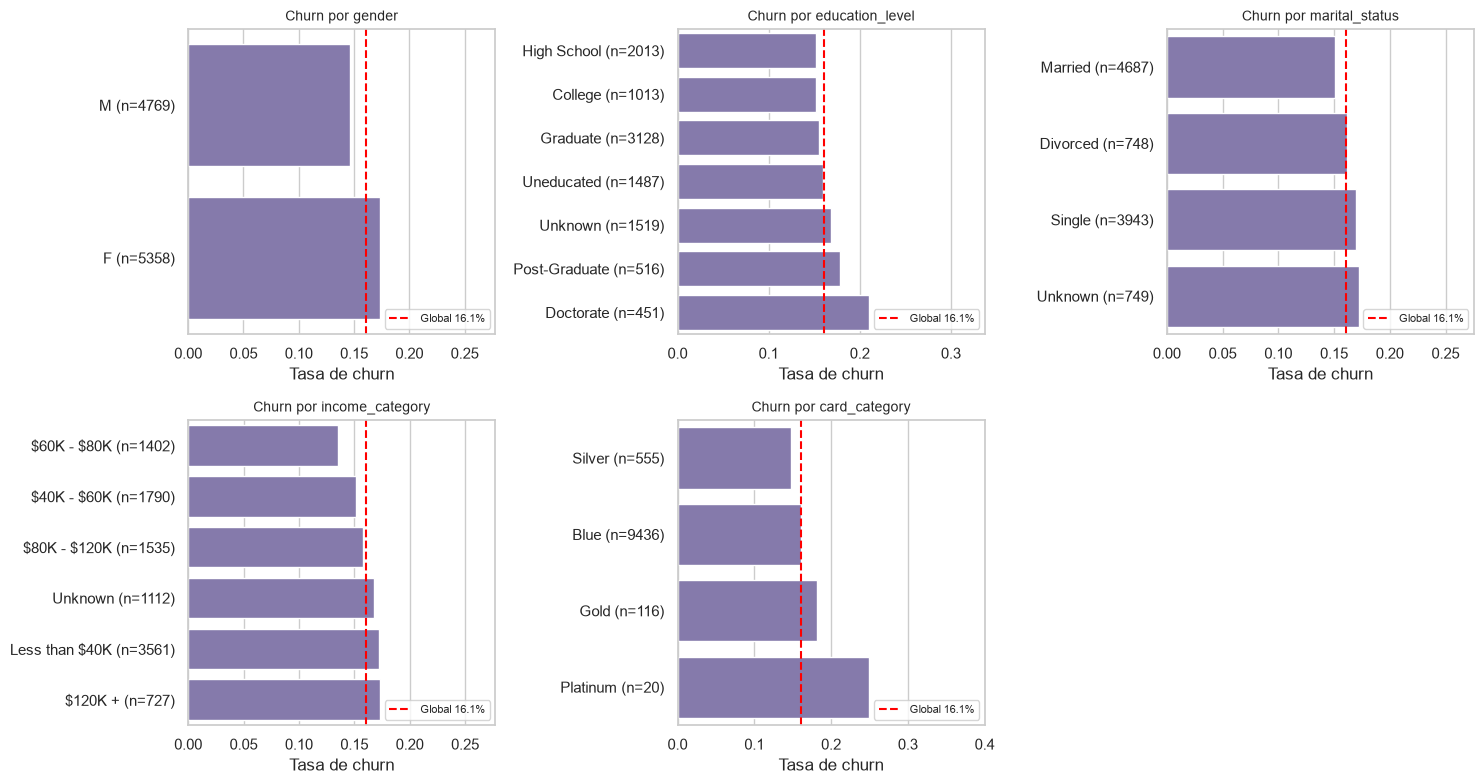

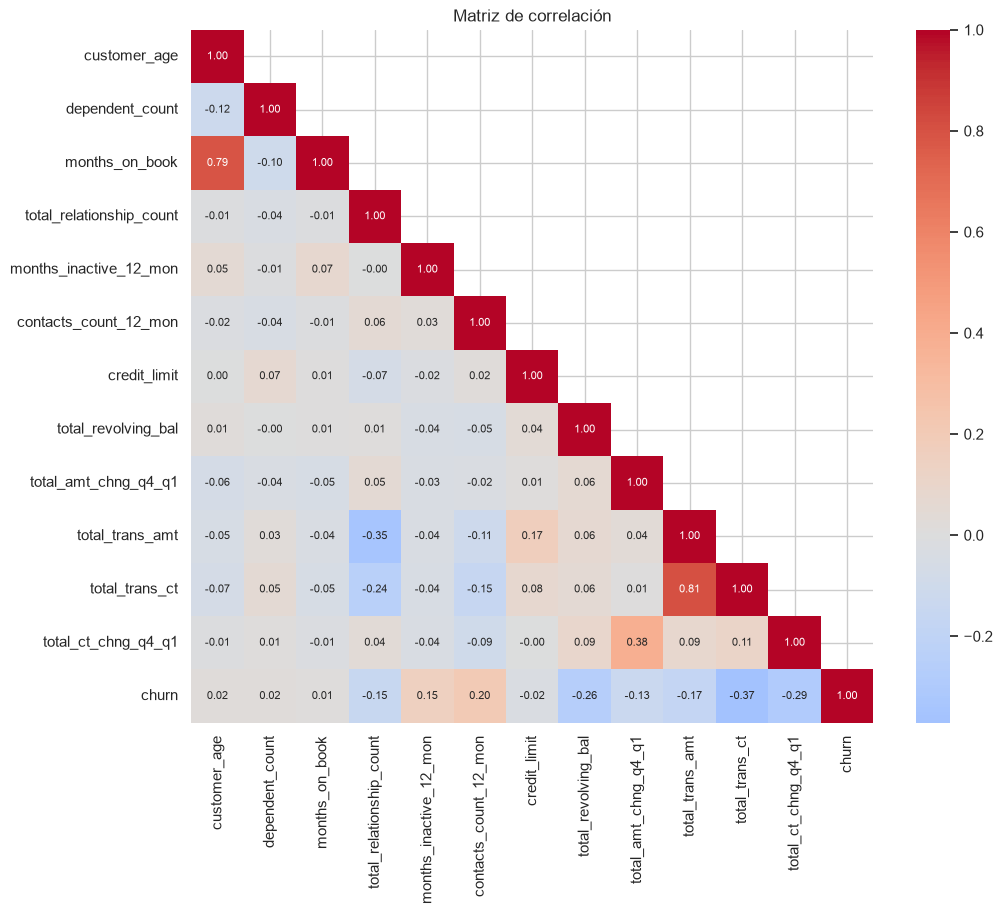

,variable,categoria,clientes,churn_%
0,gender,F,5358,17.4
1,gender,M,4769,14.6
2,education_level,College,1013,15.2
3,education_level,Doctorate,451,21.1
4,education_level,Graduate,3128,15.6
5,education_level,High School,2013,15.2
6,education_level,Post-Graduate,516,17.8
7,education_level,Uneducated,1487,15.9
8,education_level,Unknown,1519,16.9
9,marital_status,Divorced,748,16.2


In [7]:
# Comparo el churn por categoría y reviso las correlaciones
eda.plot_categoricas_churn(df)
eda.plot_correlaciones(df)
eda.tabla_churn_categorias(df)

### Análisis: churn por categoría y correlaciones

Qué muestran los gráficos:

- **Categorías:** el churn es parecido en casi todas, entre 13% y 18%, cerca del 16,1% global. Género, estado civil, educación, ingreso y tarjeta separan poco a quien se va.
- **Unknown:** su churn (17% en educación, estado civil e ingreso) es casi igual al resto. Esto respalda dejarlos como una categoría propia.
- **Grupos pequeños:** Platinum (25%, 20 clientes) y Gold (18%, 116 clientes) tienen muy pocos clientes, así que esas tasas no son confiables. Doctorado (21%, 451 clientes) es algo más alto, pero la diferencia es pequeña.
- **Correlación con churn:** las más fuertes son total_trans_ct (-0,37), total_ct_chng_q4_q1 (-0,29), total_revolving_bal (-0,26) y contacts_count_12_mon (0,20). Edad, meses en el banco, dependientes y cupo casi no se relacionan con el churn.
- **Entre variables:** total_trans_amt y total_trans_ct (0,81) y customer_age con months_on_book (0,79) están muy relacionadas, es decir, dicen casi lo mismo.
- **Tabla:** trae las mismas tasas con el número de clientes de cada categoría, para usar en el informe.

Para el banco: la actividad del cliente (transacciones y saldo) predice mejor el churn que sus datos demográficos.

## SVM: búsqueda de hiperparámetros

In [8]:
# Busco los mejores hiperparámetros del SVM (si ya los busqué antes, los cargo)
busqueda = utils.cacheado("busqueda_svm", lambda: svm.buscar_hiperparametros(datos))
svm.resumen_busqueda(busqueda)

Cargado desde models/cache: busqueda_svm


,kernel,C,gamma,grado,class_weight,pr_auc,pr_auc_std,roc_auc,recall,f1,seg_ajuste
0,rbf,5.0,0.03,-,ninguno,0.8843,0.0052,0.9697,0.7274,0.7867,1.2313
1,rbf,5.0,scale,-,ninguno,0.8821,0.0050,0.9693,0.7635,0.8021,1.5572
2,rbf,50.0,0.01,-,ninguno,0.8818,0.0036,0.9682,0.7351,0.7871,1.4404
3,rbf,20.0,0.03,-,ninguno,0.8817,0.0048,0.9688,0.7558,0.7944,1.7547
4,rbf,100.0,0.01,-,ninguno,0.8813,0.0038,0.9679,0.7427,0.7869,1.7438
5,rbf,20.0,0.01,-,ninguno,0.8793,0.0061,0.9676,0.7182,0.7812,1.5432
6,rbf,1.0,scale,-,ninguno,0.8770,0.0076,0.9684,0.7005,0.7745,1.3285
7,rbf,1.0,0.1,-,ninguno,0.8751,0.0069,0.9677,0.7082,0.7801,1.6443
8,rbf,50.0,0.03,-,ninguno,0.8729,0.0093,0.9660,0.7750,0.7885,1.7829
9,rbf,5.0,0.1,-,ninguno,0.8717,0.0083,0.9658,0.7581,0.7936,2.0616


## SVM: heatmap de validación cruzada y mejores parámetros

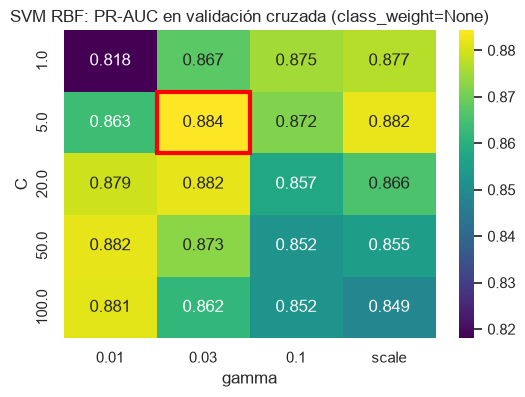

{'C': 5, 'class_weight': None, 'gamma': 0.03, 'kernel': 'rbf'}

In [9]:
# Veo el heatmap y me quedo con los mejores parámetros
svm.plot_heatmap_cv(busqueda)
params_svm = svm.mejores_parametros(busqueda)
params_svm

### Análisis: búsqueda y heatmap del SVM

- Se probaron 58 combinaciones con validación cruzada de 5 partes (290 ajustes). La mejor es RBF con C=5 y gamma=0.03, con PR-AUC de 0,884.
- **Zona buena:** C entre 5 y 100 con gamma de 0,01 a 0,03 da PR-AUC entre 0,862 y 0,884.
- **Subajuste:** con C=1 y gamma=0.01 baja a 0,818, porque el modelo es demasiado simple.
- **Sobreajuste:** con C de 50 o más y gamma de 0,1 o scale baja a 0,849 a 0,855, porque el modelo se ajusta demasiado a cada cliente.
- La desviación entre partes es pequeña (0,004 a 0,005), así que el resultado es estable.

## SVM: comparación de kernels

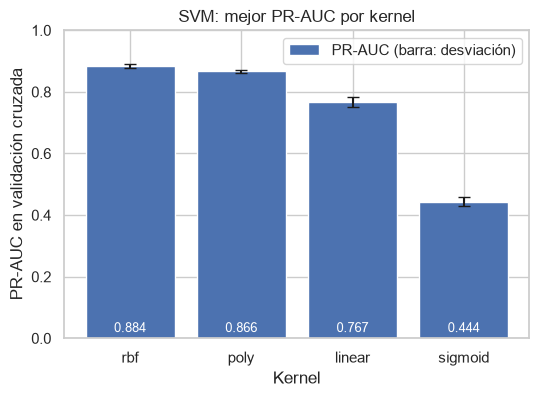

,kernel,pr_auc,pr_auc_std,roc_auc,recall,f1,mejores_parametros
0,rbf,0.8843,0.0052,0.9697,0.7274,0.7867,"C=5, class_weight=None, gamma=0.03"
1,poly,0.8664,0.0060,0.9620,0.7135,0.7709,"C=5, class_weight=None, degree=2, gamma=scale"
2,linear,0.7668,0.0165,0.9205,0.5669,0.6606,"C=0.1, class_weight=None"
3,sigmoid,0.4439,0.0138,0.8069,0.4977,0.5000,"C=5, class_weight=None, gamma=scale"


In [10]:
# Comparo los kernels
svm.plot_kernels(busqueda)
svm.tabla_por_kernel(busqueda)

### Análisis: kernels y peso de clases del SVM

- **Kernels:** RBF 0,884, polinomial (grado 2) 0,866, lineal 0,767 y sigmoide 0,444 de PR-AUC en validación cruzada.
- Los datos no son linealmente separables: el kernel lineal queda 0,12 por debajo del RBF. El sigmoide no sirve para estos datos.
- RBF le gana al polinomial por 0,018, más que su desviación (0,005 a 0,006), así que se elige RBF.
- **Peso de clases:** las 10 mejores combinaciones son todas sin class_weight. Quitarlo sube la PR-AUC de 0,866 a 0,884. Como el umbral se ajusta después, el peso no hace falta.
- **Empate:** cinco combinaciones de C y gamma quedan entre 0,881 y 0,884. Se elige C=5 y gamma=0.03, pero no es claramente mejor que las vecinas.

## SVM final: umbral y evaluación en el set de prueba

In [11]:
# Entreno el SVM final, elijo su umbral con el entrenamiento y lo evalúo en prueba
modelo_svm, umbral_svm, resultados = fl.svm_final(datos, params_svm)

Cargado desde models/cache: final_svm


## SVM: matriz de confusión, curvas y lift

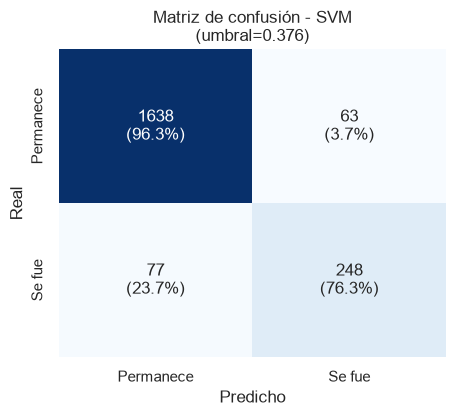

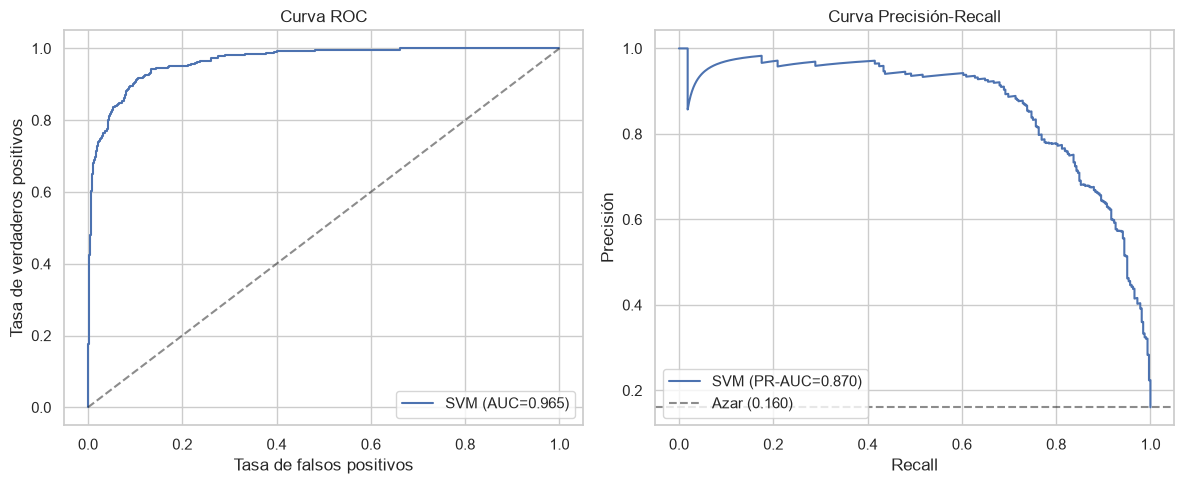

,decil,clientes,fugas,tasa_churn_%,captura_acum_%,lift
0,1,203,191,94.1,58.8,5.87
1,2,203,86,42.4,85.2,2.64
2,3,203,32,15.8,95.1,0.98
3,4,203,9,4.4,97.8,0.28
4,5,203,5,2.5,99.4,0.15
5,6,203,1,0.5,99.7,0.03
6,7,202,0,0.0,99.7,0.00
7,8,202,1,0.5,100.0,0.03
8,9,202,0,0.0,100.0,0.00
9,10,202,0,0.0,100.0,0.00


In [12]:
# Reviso la matriz de confusión, las curvas y el lift
ev.plot_matriz_confusion(resultados["SVM"], archivo="svm/confusion")
ev.plot_curvas(resultados)
ev.tabla_lift(resultados["SVM"])

### Análisis: evaluación del SVM en el set de prueba

- **Umbral:** 0,376, elegido con validación cruzada del entrenamiento. Es menor que 0,5 para detectar más fugas, que son pocas.
- **Métricas:** recall 0,763, precisión 0,797, F1 0,780, ROC-AUC 0,965 y PR-AUC 0,870. La PR-AUC es algo menor que en validación cruzada (0,884), una diferencia normal en un set de prueba con solo 325 fugas.
- **Matriz de confusión:** de las 325 fugas, 248 se detectan (76,3%) y 77 no (23,7%). De 1.701 clientes que se quedan, 63 se marcan por error (3,7%).
- **Curvas:** la ROC queda muy por encima del azar. En la curva de precisión y recall, la precisión se mantiene sobre 0,9 hasta cerca de un recall de 0,6 y cae desde 0,8. El azar sería 0,160.
- **Lift:** el primer decil tiene 94,1% de fugas (lift 5,87) y captura 58,8% del total. Con los dos primeros deciles se alcanza 85,2%, y con tres 95,1%. Desde el decil 4 casi no quedan fugas.

Para el banco: contactar al 20% de los clientes con mayor riesgo alcanza a 85% de quienes se irían.

## SVM: importancia de las variables

Cargado desde models/cache: importancia_svm


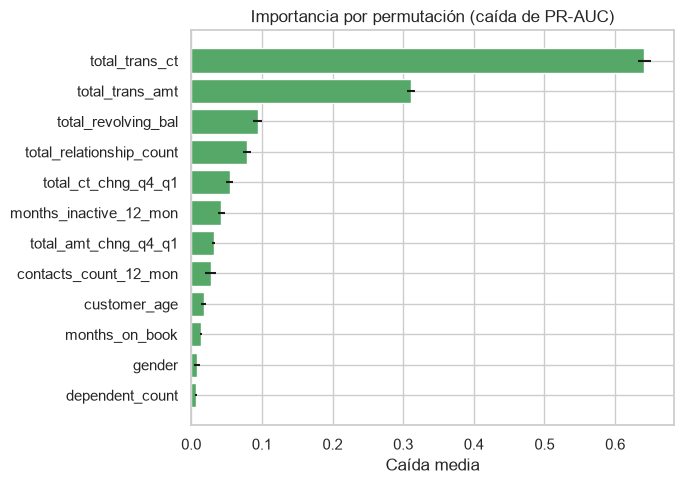

In [13]:
# Veo qué variables pesan más en el SVM
imp_svm = utils.cacheado("importancia_svm", lambda: ev.importancia_permutacion(modelo_svm, datos.X_test, datos.y_test))
ev.plot_importancia(imp_svm)

### Análisis: importancia de las variables del SVM

- **Actividad:** total_trans_ct (caída de 0,64 en PR-AUC) y total_trans_amt (0,31) pesan mucho más que las demás. Si se mezclan sus valores, el modelo pierde casi toda su capacidad.
- **Saldo y relación:** total_revolving_bal, total_relationship_count y total_ct_chng_q4_q1 vienen después, con caídas de 0,05 a 0,09.
- **Datos personales:** género, dependientes, meses en el banco y edad casi no pesan, igual que en la correlación con churn.
- Las dos variables de transacciones están muy relacionadas (0,81), así que su importancia se reparte entre ambas.

Para el banco: la señal está en cuánto usa el cliente su tarjeta, y no en quién es.

## SVM con más de dos clases (demostración)

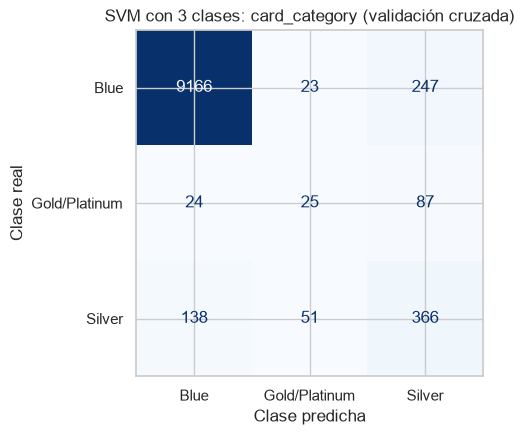

,precisión,recall,f1-score,clientes
Blue,0.983,0.971,0.977,9436
Gold/Platinum,0.253,0.184,0.213,136
Silver,0.523,0.659,0.583,555
macro avg,0.586,0.605,0.591,10127


In [14]:
# Pruebo el SVM con más de dos clases (categoría de tarjeta)
svm.demo_multiclase(datos, df)

### Análisis: SVM con más de dos clases

- El churn es un problema de dos clases, así que esto es solo una demostración de la técnica. Se predice la categoría de tarjeta, uniendo Gold y Platinum porque Platinum tiene solo 20 clientes.
- Con más de dos clases, el SVM compara las clases de a pares ("uno contra uno") y gana la clase que más veces se elige.
- Blue se acierta casi siempre (recall 0,97), pero Gold/Platinum es difícil (recall 0,18) porque son pocos clientes.
- La exactitud global (0,94) engaña, por la cantidad de clientes Blue. Por eso se mira el promedio por clase: recall 0,61 y F1 0,59.

## Regresión logística: modelo de referencia

In [15]:
# Busco los mejores hiperparámetros de la regresión logística, la entreno y la evalúo en prueba
modelo_rl = fl.regresion_logistica(datos, resultados)

Cargado desde models/cache: busqueda_regresion_logistica


,C,class_weight,pr_auc,pr_auc_std,roc_auc,recall,f1,seg_ajuste
0,0.10,ninguno,0.7643,0.0157,0.9235,0.5707,0.6585,0.1001
1,0.30,ninguno,0.7637,0.0166,0.9243,0.5807,0.6636,0.0947
2,1.00,ninguno,0.7633,0.0168,0.9244,0.5868,0.6651,0.0865
3,0.03,ninguno,0.7628,0.0143,0.9207,0.5400,0.6432,0.0730
4,10.00,ninguno,0.7627,0.0172,0.9245,0.5906,0.6675,0.0805


{'C': 0.1, 'class_weight': None}
Cargado desde models/cache: final_regresion_logistica


,variable,coeficiente
0,total_trans_ct,-2.449
1,total_trans_amt,1.324
2,total_revolving_bal,-0.747
3,total_relationship_count,-0.718
4,total_ct_chng_q4_q1,-0.657
5,contacts_count_12_mon,0.542
6,months_inactive_12_mon,0.490
7,gender_F,0.334
8,gender_M,-0.333
9,marital_status_Married,-0.332


### Análisis: regresión logística

- Es el modelo más simple y sirve de punto de partida. Usa la misma partición, la misma validación cruzada de 5 partes y las mismas funciones de evaluación que los demás.
- Se probaron 18 combinaciones. La mejor es C=0.1 sin class_weight, con PR-AUC de 0,764 en validación cruzada. Las combinaciones con C entre 0.1 y 10 quedan casi iguales (de 0,763 a 0,764), así que el resultado es estable.
- **Prueba:** umbral 0,355, recall 0,671, precisión 0,701, F1 0,686, ROC-AUC 0,915 y PR-AUC 0,737. De las 325 fugas se detectan 218 (67,1%) y 107 no. De 1.701 clientes que se quedan, 93 se marcan por error.
- **Variables:** pesan más total_trans_ct (menos transacciones, más fuga), total_revolving_bal, total_relationship_count y total_ct_chng_q4_q1. Es la misma actividad que destacan los otros modelos.
- Queda por debajo del SVM (0,870) y de los ensambles (de 0,936 a 0,968). Como una línea recta no capta bien las relaciones entre las variables, se justifica usar modelos más complejos.
- Sirve como validación: el resultado coincide con el de PyCaret (PR-AUC 0,738 en prueba y 0,761 en validación cruzada).


## Ensambles: búsqueda de hiperparámetros

In [16]:
# Busco los mejores hiperparámetros de cada ensamble
mejores_ens = fl.buscar_ensambles(datos)

Cargado desde models/cache: busqueda_Bagging

=== Bagging ===


,pr_auc,pr_auc_std,roc_auc,recall,f1,seg_ajuste,estimator__class_weight,estimator__max_depth,estimator__min_samples_leaf,max_samples,n_estimators
0,0.9393,0.0165,0.9854,0.8472,0.8725,4.6461,None,16,2,0.9744,109
1,0.9390,0.0167,0.9856,0.8480,0.8764,4.8169,None,16,1,0.6294,153
2,0.9381,0.0169,0.9866,0.8617,0.8711,6.5263,balanced,12,2,0.7839,195
3,0.9380,0.0161,0.9858,0.8433,0.8724,3.1488,None,16,1,0.8557,82
4,0.9363,0.0180,0.9857,0.8617,0.8708,3.1873,balanced,12,2,0.6523,102


Cargado desde models/cache: busqueda_Random Forest

=== Random Forest ===


,pr_auc,pr_auc_std,roc_auc,recall,f1,seg_ajuste,class_weight,max_depth,max_features,min_samples_leaf,n_estimators
0,0.9546,0.0123,0.9898,0.8280,0.8735,3.8364,None,12,0.3,1,249
1,0.9538,0.0116,0.9897,0.8287,0.8749,7.8716,None,20,0.3,2,464
2,0.9529,0.0123,0.9895,0.8472,0.8789,13.6608,None,None,0.5,2,587
3,0.9514,0.0122,0.9889,0.8403,0.8769,6.0707,None,12,0.5,3,287
4,0.9501,0.0134,0.9887,0.8410,0.8746,10.2937,None,20,0.5,4,463


Cargado desde models/cache: busqueda_XGBoost

=== XGBoost ===


,pr_auc,pr_auc_std,roc_auc,recall,f1,seg_ajuste,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,scale_pos_weight,subsample
0,0.9706,0.0061,0.9934,0.9347,0.9069,0.9839,0.8777,0.0532,4,4,459,0.5492,5.222,0.9101
1,0.9701,0.0068,0.9930,0.9217,0.9147,0.9738,0.9744,0.1848,4,2,414,0.5245,5.222,0.8737
2,0.9696,0.0065,0.9932,0.8856,0.9093,0.9777,0.6524,0.0292,5,1,467,0.9726,1.000,0.7078
3,0.9695,0.0060,0.9929,0.9109,0.9103,1.0621,0.9697,0.1570,6,1,339,1.3251,5.222,0.8989
4,0.9695,0.0067,0.9932,0.8856,0.9098,0.7012,0.5202,0.1027,4,2,328,0.5494,1.000,0.7901


Cargado desde models/cache: busqueda_LightGBM

=== LightGBM ===


,pr_auc,pr_auc_std,roc_auc,recall,f1,seg_ajuste,class_weight,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,subsample
0,0.9716,0.0066,0.9932,0.9155,0.9156,0.9307,balanced,0.6976,0.1689,40,453,29,0.1503,0.6784
1,0.9715,0.0062,0.9934,0.9255,0.9167,0.7729,balanced,0.5998,0.0654,12,456,21,0.2193,0.6260
2,0.9712,0.0065,0.9933,0.8902,0.9101,0.6820,None,0.6915,0.1874,12,406,19,1.3260,0.9084
3,0.9712,0.0066,0.9935,0.8863,0.9118,0.6074,None,0.5385,0.0390,31,433,16,1.7730,0.7183
4,0.9708,0.0073,0.9933,0.8856,0.9126,0.9057,None,0.6572,0.0645,39,380,59,1.2014,0.6812


### Análisis: búsqueda de los ensambles

- Cada ensamble se probó con 20 combinaciones al azar y validación cruzada de 5 partes (100 ajustes).
- **PR-AUC en validación cruzada:** LightGBM 0,972, XGBoost 0,971, Random Forest 0,955 y Bagging 0,939. El boosting supera a los de bagging por cerca de 0,02.
- **Estabilidad:** la desviación entre partes es de 0,006 a 0,007 en el boosting, contra 0,012 en Random Forest y 0,017 en Bagging. El boosting da resultados más parejos.
- **Velocidad:** LightGBM y XGBoost ajustan en cerca de 1 segundo, Bagging en 4 a 8 y Random Forest en 4 a 15.
- Las cinco mejores combinaciones de cada modelo difieren muy poco (LightGBM entre 0,971 y 0,972), así que ninguno es sensible a un hiperparámetro en particular.
- **Peso de clases:** en XGBoost y LightGBM las mejores combinaciones mezclan con peso y sin peso, así que no es decisivo. Como el umbral se ajusta después, no hace falta.

## Ensambles: modelos finales y evaluación en el set de prueba

In [17]:
# Entreno los ensambles finales y los evalúo en prueba
modelos = {"SVM": modelo_svm, "Regresion logistica": modelo_rl}
fl.entrenar_ensambles(datos, mejores_ens, resultados, modelos)

Cargado desde models/cache: final_Bagging
Cargado desde models/cache: final_Random Forest
Cargado desde models/cache: final_XGBoost
Cargado desde models/cache: final_LightGBM


## Stacking

In [18]:
# Combino el SVM, Random Forest, XGBoost y LightGBM en un Stacking
fl.stacking(datos, params_svm, mejores_ens, resultados, modelos)

Cargado desde models/cache: final_stacking


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,umbral
XGBoost,0.972,0.935,0.944,0.880,0.911,0.993,0.968,0.611
Stacking,0.972,0.947,0.916,0.911,0.914,0.992,0.967,0.305
LightGBM,0.971,0.943,0.916,0.902,0.909,0.992,0.966,0.361
Random Forest,0.961,0.923,0.887,0.868,0.877,0.988,0.953,0.356
Bagging,0.960,0.929,0.870,0.883,0.876,0.984,0.936,0.244
SVM,0.931,0.863,0.797,0.763,0.780,0.965,0.870,0.376
Regresion logistica,0.901,0.808,0.701,0.671,0.686,0.915,0.737,0.355


### Análisis: ensambles y Stacking en el set de prueba

- **Orden por PR-AUC:** XGBoost 0,968, Stacking 0,967, LightGBM 0,966, Random Forest 0,953, Bagging 0,936 y SVM 0,870.
- Stacking tiene el mejor recall (0,911) y F1 (0,914). LightGBM tiene recall 0,902 y precisión 0,916. XGBoost tiene la precisión más alta (0,944) y detecta menos fugas (recall 0,880).
- **Stacking:** combina cuatro modelos y mejora la PR-AUC de LightGBM en solo 0,001, una diferencia sin importancia práctica. Su umbral (0,305) es el más bajo de los tres, así que contacta más clientes.
- **Sin sobreajuste:** la PR-AUC en prueba es casi igual a la de validación cruzada (LightGBM 0,966 contra 0,972 y XGBoost 0,968 contra 0,971).
- Cada modelo tiene su propio umbral (de 0,244 a 0,611), elegido con validación cruzada del entrenamiento. Por eso no se comparan con el mismo umbral fijo.

## Redes neuronales: red base

Entreno una red feed-forward de Keras con 2 capas ocultas (32 y 16 neuronas), sin ajustar, para tener un punto de partida. Usa los mismos datos, la misma partición 80/20 y las mismas funciones de evaluación que los otros modelos.

In [19]:
# Entreno la red base, elijo su umbral con el entrenamiento y la evalúo en prueba
fl.red_base(datos, resultados, modelos)
ev.tabla_comparativa(resultados).loc[["Red base"]]

Cargado desde models/cache: final_red_base


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,umbral
Red base,0.929,0.852,0.805,0.738,0.77,0.962,0.853,0.434


### Análisis: red base

- La red base (2 capas de 32 y 16 neuronas, sin ajustar) detecta el 73,8% de los clientes que se fueron (recall) y tiene PR-AUC de 0,853.
- Ya queda cerca del SVM (0,870) y por encima de la red sin ajustar de PyCaret (0,798).
- El umbral de decisión (0,434) se eligió con validación cruzada del entrenamiento, no con la prueba.

## Redes neuronales: búsqueda de hiperparámetros

In [20]:
# Pruebo 15 configuraciones al azar con validación cruzada y me quedo con la de mayor PR-AUC
params_red = fl.buscar_red(datos)
params_red

Cargado desde models/cache: busqueda_red
Mejor PR-AUC en validación cruzada: 0.883


,param_red__optimizador,param_red__momentum,param_red__lr,param_red__l2,param_red__dropout,param_red__decaimiento,param_red__capas,param_red__batch_size,mean_test_score,std_test_score
5,adam,0.0,0.0030,0.0010,0.0,0.01,"(32, 16)",128,0.882632,0.011067
8,rmsprop,0.0,0.0003,0.0001,0.1,0.00,"(64,)",64,0.880797,0.006389
9,rmsprop,0.9,0.0010,0.0100,0.0,0.01,"(16,)",32,0.879257,0.006023
12,rmsprop,0.9,0.0010,0.0000,0.2,0.00,"(32,)",64,0.876391,0.007239
11,rmsprop,0.9,0.0010,0.0000,0.2,0.01,"(64, 32, 16)",32,0.874503,0.009250


{'optimizador': 'adam',
 'momentum': 0.0,
 'lr': 0.003,
 'l2': 0.001,
 'dropout': 0.0,
 'decaimiento': 0.01,
 'capas': (32, 16),
 'batch_size': 128}

### Análisis: búsqueda de hiperparámetros

- Se probaron 15 combinaciones al azar (capas, Dropout, L2, optimizador, tasa de aprendizaje y tamaño del lote), con validación cruzada de 5 partes solo en el entrenamiento.
- La mejor tiene PR-AUC de 0,883 en validación cruzada, igual que el SVM (0,884).
- Las 5 mejores quedan entre 0,875 y 0,883, dentro de la variación normal (0,006 a 0,011). Es un empate técnico, no hay una configuración claramente mejor.
- La elegida usa Adam, 2 capas (32 y 16 neuronas), L2 de 0,001, sin Dropout, lote de 128 y tasa de aprendizaje de 0,003 con decaimiento.
- La búsqueda queda guardada en la caché, así que no se repite (la primera vez tarda unos 10 minutos).

## Red neuronal final y evaluación en el set de prueba

In [21]:
# Entreno la red con los mejores parámetros y la evalúo en prueba
modelo_red = fl.red_final(datos, params_red, resultados, modelos)
ev.tabla_comparativa(resultados).loc[["Red base", "Red neuronal"]]

Cargado desde models/cache: final_red_neuronal


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,umbral
Red base,0.929,0.852,0.805,0.738,0.770,0.962,0.853,0.434
Red neuronal,0.939,0.867,0.846,0.760,0.801,0.969,0.886,0.448


### Análisis: red neuronal final

- Con la mejor configuración, en prueba la PR-AUC sube de 0,853 a 0,886, el recall de 0,738 a 0,760 y el F1 de 0,770 a 0,801.
- Queda por encima del SVM (PR-AUC 0,870 y F1 0,780), pero esa diferencia cabe dentro del margen de más o menos 0,02 de la prueba (325 fugas).
- La PR-AUC en prueba (0,886) casi coincide con la de validación cruzada (0,883). Esto indica que la red generaliza y no solo memoriza.

## Aprendizaje de la red por época

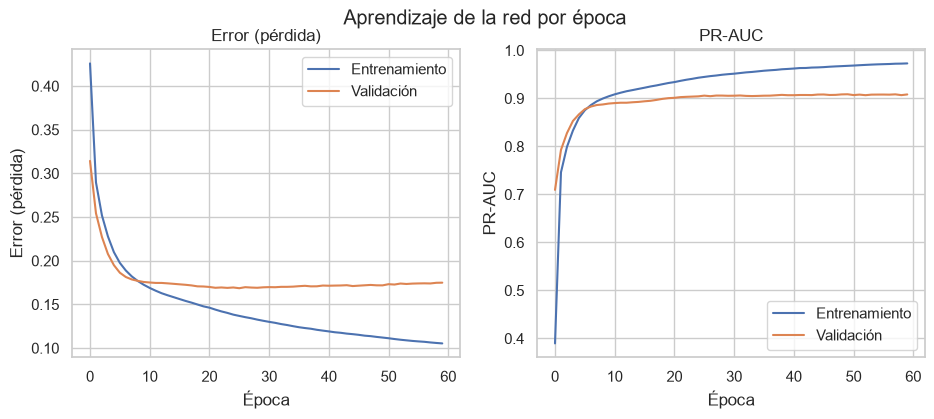

In [22]:
# Grafico cómo cambian el error y la PR-AUC en cada época, en entrenamiento y validación
mk.plot_aprendizaje(modelo_red)

### Análisis: aprendizaje por época

- En cada época la red hace la fase forward (calcula la predicción), mide el error y hace la fase backward (back-propagation), que corrige los pesos para reducirlo.
- El error y la PR-AUC de validación dejan de mejorar hacia la época 20 (PR-AUC cerca de 0,90).
- El entrenamiento sigue mejorando (PR-AUC cerca de 0,97). Esa brecha es un sobreajuste leve: la red empieza a memorizar.
- La parada temprana vigila la PR-AUC de validación y se queda con los pesos de la mejor época, no con los de la última.

## Comparación de optimizadores (método del gradiente)

La red aprende minimizando el error con el método del gradiente: el back-propagation calcula el gradiente y el optimizador lo usa para corregir los pesos. Aquí entreno la red final tres veces, cambiando solo el optimizador (SGD, RMSprop y Adam).

Cargado desde models/cache: optimizadores_red


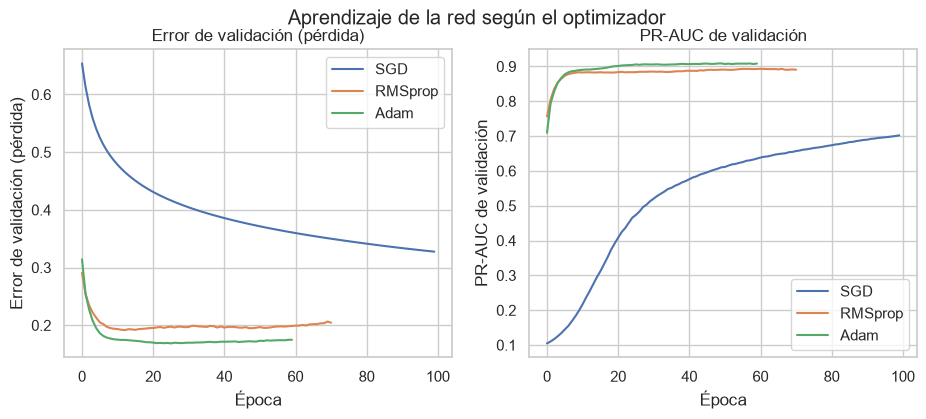

,épocas,pr_auc_validación,pr_auc_prueba
optimizador,,,
SGD,100,0.702,0.674
RMSprop,71,0.893,0.863
Adam,60,0.909,0.886


In [23]:
# Entreno la red final con SGD, RMSprop y Adam y comparo cómo aprende cada una
tabla_opt, hist_opt = utils.cacheado("optimizadores_red", lambda: mk.comparar_optimizadores(datos, params_red))
mk.plot_optimizadores(hist_opt)
tabla_opt

### Análisis: optimizadores

- Los tres optimizadores usan el método del gradiente: el back-propagation calcula el gradiente del error y el optimizador lo usa para corregir los pesos. Cambia cómo da cada paso.
- SGD (sin momentum y con la misma tasa de aprendizaje de 0,003) aprende muy lento. Llega al máximo de 100 épocas sin terminar de aprender: el error de validación baja de 0,654 a 0,328 y la PR-AUC queda en 0,702 en validación y 0,674 en prueba.
- RMSprop y Adam bajan el error desde las primeras épocas. Con solo 5 épocas ya tienen PR-AUC de validación cercana a 0,87, mientras SGD tiene 0,13.
- Adam es el mejor: PR-AUC de 0,909 en validación y 0,886 en prueba, contra 0,893 y 0,863 de RMSprop. Es el que eligió la búsqueda de hiperparámetros.
- SGD usa el mismo paso para todos los pesos. RMSprop y Adam ajustan el paso de cada peso según el tamaño de sus gradientes recientes, y Adam además usa momentum. Por eso aprenden más rápido con la misma tasa.
- La comparación deja la misma tasa para ver solo el efecto del optimizador. Con otra tasa o con momentum, SGD se acercaría más.

## Matriz de confusión y lift de la red final

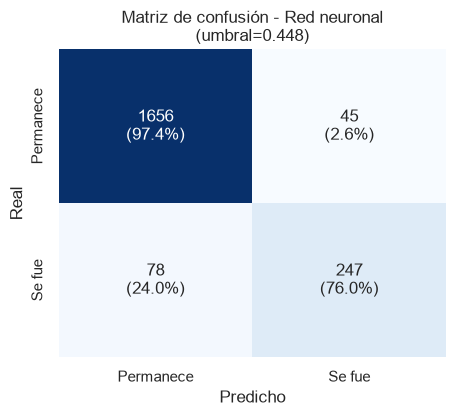

,decil,clientes,fugas,tasa_churn_%,captura_acum_%,lift
0,1,203,190,93.6,58.5,5.83
1,2,203,93,45.8,87.1,2.86
2,3,203,29,14.3,96.0,0.89
3,4,203,8,3.9,98.5,0.25
4,5,203,3,1.5,99.4,0.09
5,6,203,1,0.5,99.7,0.03
6,7,202,1,0.5,100.0,0.03
7,8,202,0,0.0,100.0,0.00
8,9,202,0,0.0,100.0,0.00
9,10,202,0,0.0,100.0,0.00


In [24]:
# Miro la matriz de confusión y el lift de la red final en el set de prueba
ev.plot_matriz_confusion(resultados["Red neuronal"], archivo="redes/confusion")
ev.tabla_lift(resultados["Red neuronal"])

### Análisis: matriz de confusión y lift

- De 325 clientes que se fueron, la red detectó 247 (76,0%) y se le escaparon 78. Un falso negativo es un cliente que se va sin que el banco lo detecte.
- De 1.701 clientes que se quedaron, marcó 45 como riesgo (2,6%). Son falsas alarmas y su costo es ofrecerle un beneficio a quien no se iba.
- Contactando al 10% de clientes de mayor riesgo se alcanza el 58,5% de las fugas. Con el 20% se llega al 87,1% y con el 30% al 96,0%.
- El primer decil tiene 93,6% de churn real (5,8 veces el promedio) y desde el decil 5 casi no quedan fugas.
- LightGBM concentra algo más (61,8%, 95,7% y 100% con el 10%, 20% y 30%), pero la red queda cerca.

## Efecto de la regularización

In [25]:
# Comparo la red sin regularizar, con L2, con Dropout y con ambos, para ver el efecto en el sobreajuste
utils.cacheado("regularizacion_red", lambda: mk.tabla_regularizacion(datos, params_red))

Cargado desde models/cache: regularizacion_red


,épocas,pr_auc_entrenamiento,pr_auc_validación,pr_auc_prueba,brecha
configuración,,,,,
Sin regularización,23,0.923,0.887,0.856,0.035
Solo L2,60,0.968,0.909,0.886,0.059
Solo Dropout,47,0.898,0.888,0.852,0.010
L2 y Dropout,74,0.906,0.906,0.872,-0.000


### Análisis: efecto de la regularización

- La regularización limita el sobreajuste. L2 castiga los pesos grandes y Dropout apaga al azar el 30% de las neuronas en cada paso del entrenamiento.
- Dropout cierra la brecha entre entrenamiento y validación (de 0,035 a 0,010, y a 0,000 junto con L2), pero no mejora la prueba (0,852 y 0,872 contra 0,856).
- Solo L2 da la mejor PR-AUC en validación (0,909) y en prueba (0,886). Entrena más épocas (60) y aprende más, aunque su brecha sea mayor (0,059).
- Una brecha pequeña no siempre es lo mejor, lo que importa es el desempeño con clientes nuevos. Por eso la búsqueda eligió L2 sin Dropout.
- Las diferencias pequeñas (por ejemplo 0,886 contra 0,872) caben dentro del margen de más o menos 0,02 de la prueba. Solo la mejora de L2 frente a no regularizar (0,030) se ve más clara.

## Importancia de las variables de la red

Cargado desde models/cache: importancia_red


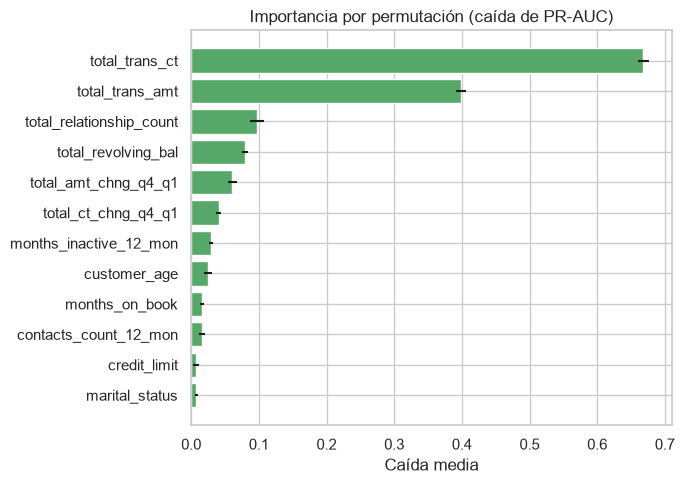

In [26]:
# Mezclo cada variable y mido cuánto cae la PR-AUC para saber cuáles pesan más en la red
imp_red = utils.cacheado("importancia_red", lambda: ev.importancia_permutacion(modelo_red, datos.X_test, datos.y_test, n_jobs=1))
ev.plot_importancia(imp_red, archivo="redes/importancia")

### Análisis: importancia de las variables

- total_trans_ct (número de transacciones) es la más importante: al mezclarla, la PR-AUC cae 0,67. Le sigue total_trans_amt (monto) con 0,40.
- Después van total_relationship_count (productos con el banco, cerca de 0,10), total_revolving_bal (saldo) y el cambio de actividad entre trimestres (total_amt_chng_q4_q1 y total_ct_chng_q4_q1).
- Quien deja de usar la tarjeta es quien se va. Es el mismo mensaje del análisis exploratorio y de los otros modelos.
- Transacciones y monto están muy relacionadas entre sí (0,81), así que se reparten la importancia y cada una se ve menos importante de lo que es.
- Edad, meses en el banco, contactos, límite de crédito y estado civil casi no pesan en la red.

## Guardado de los modelos entrenados

Los modelos y sus resultados quedan en `models/`, los modelos en `models/finales/`, para no tener que reentrenarlos cada vez que se abre el notebook.

In [27]:
# Guardo los modelos entrenados y sus resultados en la carpeta models/finales
utils.guardar_modelos(modelos, resultados)

## Cargar los modelos guardados

Si los modelos ya fueron entrenados y guardados en `models/finales/`, esta celda los carga para no tener que reentrenarlos.

In [28]:
# Cargo los modelos y resultados guardados para no reentrenar
modelos, resultados = utils.cargar_modelos()

## Comparación final de los modelos

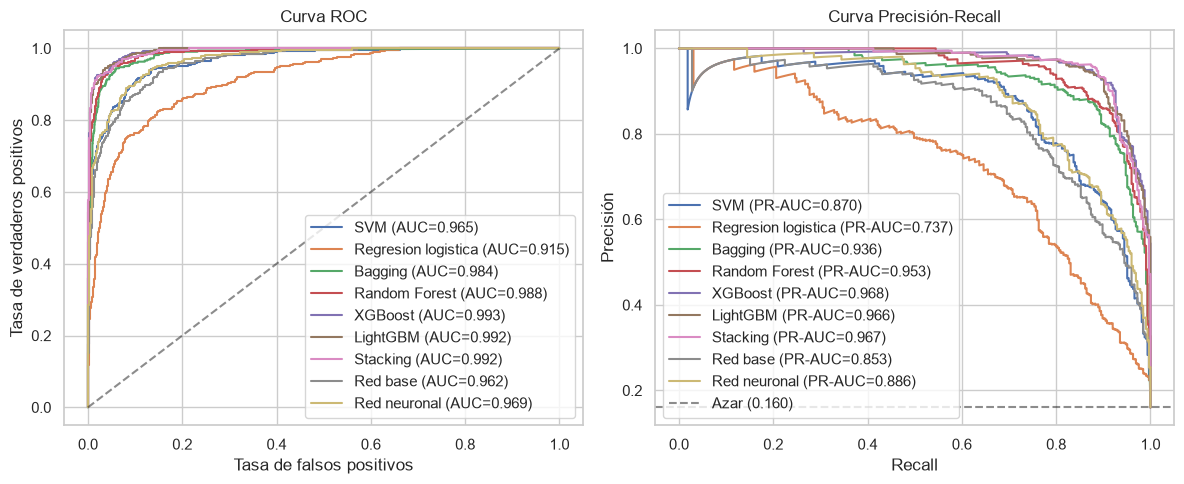

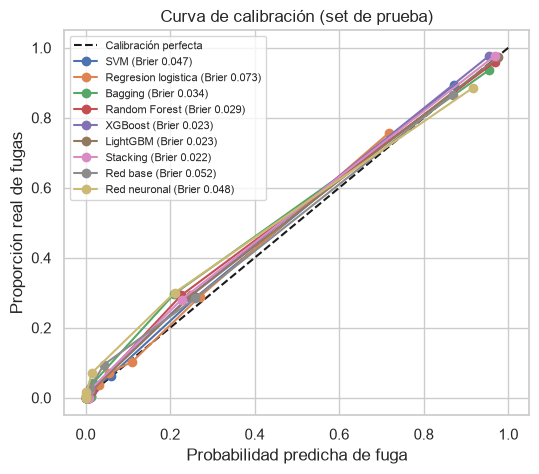

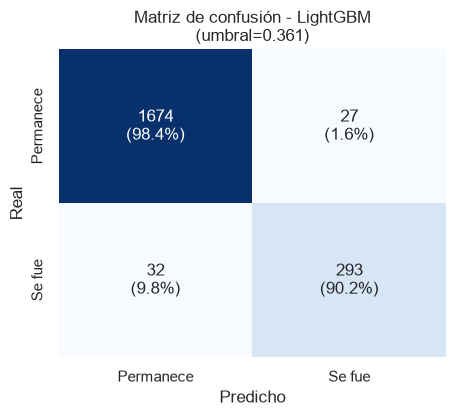

Cargado desde models/cache: importancia_lgbm


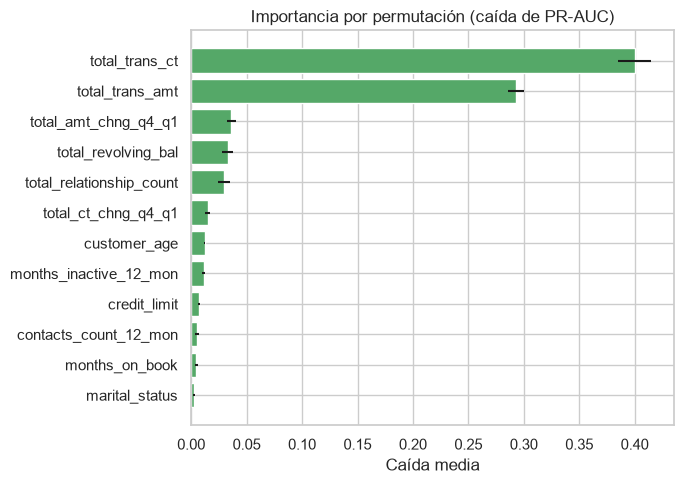

,decil,clientes,fugas,tasa_churn_%,captura_acum_%,lift
0,1,203,201,99.0,61.8,6.17
1,2,203,110,54.2,95.7,3.38
2,3,203,14,6.9,100.0,0.43
3,4,203,0,0.0,100.0,0.00
4,5,203,0,0.0,100.0,0.00
5,6,203,0,0.0,100.0,0.00
6,7,202,0,0.0,100.0,0.00
7,8,202,0,0.0,100.0,0.00
8,9,202,0,0.0,100.0,0.00
9,10,202,0,0.0,100.0,0.00


In [29]:
# Comparo todos los modelos
ev.plot_curvas(resultados, archivo="comparacion/curvas_roc_pr_todos")
ev.plot_calibracion(resultados)
ev.plot_matriz_confusion(resultados["LightGBM"], archivo="ensambles/confusion_lightgbm")
imp_lgbm = utils.cacheado("importancia_lgbm", lambda: ev.importancia_permutacion(modelos["LightGBM"], datos.X_test, datos.y_test))
ev.plot_importancia(imp_lgbm, archivo="ensambles/importancia_lgbm")
ev.tabla_lift(resultados["LightGBM"])

### Análisis: comparación final de los modelos

- **Curvas:** los cinco ensambles quedan casi juntos. La red neuronal y el SVM van por debajo, sobre todo en la curva de precisión y recall entre 0,6 y 1 de recall, y la regresión logística es la más baja.
- **Calibración:** todas las curvas quedan cerca de la diagonal, así que las probabilidades se pueden leer como riesgo real de fuga. Brier de menor a mayor: Stacking 0,022, LightGBM 0,023, XGBoost 0,023, Random Forest 0,029, Bagging 0,034, SVM 0,047, red neuronal 0,048 y regresión logística 0,073. Alrededor de una probabilidad de 0,2 todos subestiman un poco (la proporción real es cercana a 0,3).
- **Matriz de confusión de LightGBM:** con el umbral 0,361 detecta 293 de las 325 fugas (90,2%), no detecta 32 y marca por error a 27 de los 1.701 que se quedan (1,6%).
- **Importancia:** total_trans_ct (caída de 0,40 en PR-AUC) y total_trans_amt (0,29) pesan mucho más que las demás. Siguen total_amt_chng_q4_q1, total_revolving_bal y total_relationship_count (0,03 a 0,04). Es la misma conclusión que con el SVM.
- **Lift de LightGBM:** el primer decil tiene 99,0% de fugas (lift 6,17) y captura 61,8% del total. Con dos deciles se alcanza 95,7% y desde el cuarto ya no quedan fugas.

## Intervalos de confianza para comparar los modelos

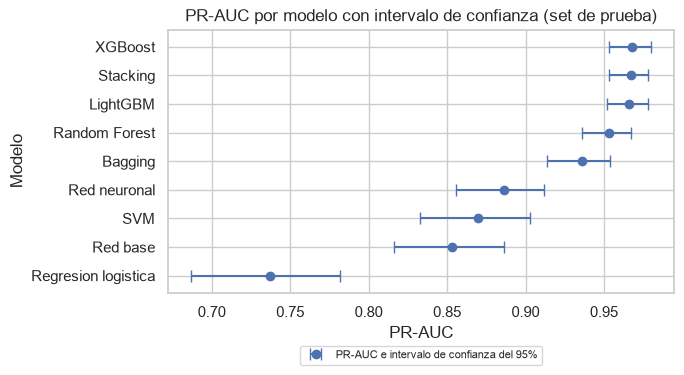

,pr_auc,pr_auc_inf,pr_auc_sup,f1,f1_inf,f1_sup
XGBoost,0.968,0.953,0.980,0.911,0.889,0.933
Stacking,0.967,0.953,0.978,0.914,0.890,0.936
LightGBM,0.966,0.952,0.978,0.909,0.886,0.931
Random Forest,0.953,0.936,0.967,0.877,0.847,0.904
Bagging,0.936,0.914,0.954,0.876,0.849,0.904
Red neuronal,0.886,0.856,0.912,0.801,0.765,0.835
SVM,0.870,0.833,0.903,0.780,0.744,0.814
Red base,0.853,0.816,0.886,0.770,0.733,0.806
Regresion logistica,0.737,0.687,0.782,0.686,0.645,0.726


In [30]:
# Calculo el intervalo de confianza de cada modelo en prueba para ver si sus diferencias son reales
tabla_ic = ev.tabla_intervalos(resultados)
ev.plot_intervalos(tabla_ic)
tabla_ic

### Análisis: intervalos de confianza

- El intervalo de confianza del 95% se calcula remuestreando 1.000 veces los clientes de prueba. Si los intervalos de dos modelos se traslapan, la diferencia entre ellos no es confiable.
- XGBoost (PR-AUC 0,968), Stacking (0,967) y LightGBM (0,966) se traslapan casi por completo (de 0,952 a 0,980). Con esta prueba no se pueden distinguir, es un empate técnico.
- Random Forest (0,953) se traslapa bastante con ellos y Bagging (0,936) apenas.
- La red neuronal (0,886, de 0,856 a 0,912) queda por debajo de los ensambles, cuyos intervalos empiezan en 0,914 o más. Se traslapa con el SVM (0,833 a 0,903), así que entre ellos hay empate técnico. Ajustarla sirvió: la red base (0,853) queda más abajo.
- El SVM (0,870) queda claramente por debajo de los ensambles: su intervalo llega hasta 0,903 y los demás empiezan en 0,914 o más. Con el F1 pasa lo mismo (0,780 contra 0,876 a 0,914).
- Como hay empate técnico, se elige LightGBM por simplicidad y rapidez. Es un solo modelo y de los más rápidos de ajustar, igual que XGBoost. El Stacking no se justifica, porque entrena 4 modelos y su mejora de 0,001 está muy dentro del margen.

## Curva de ganancia: a cuántos clientes contactar

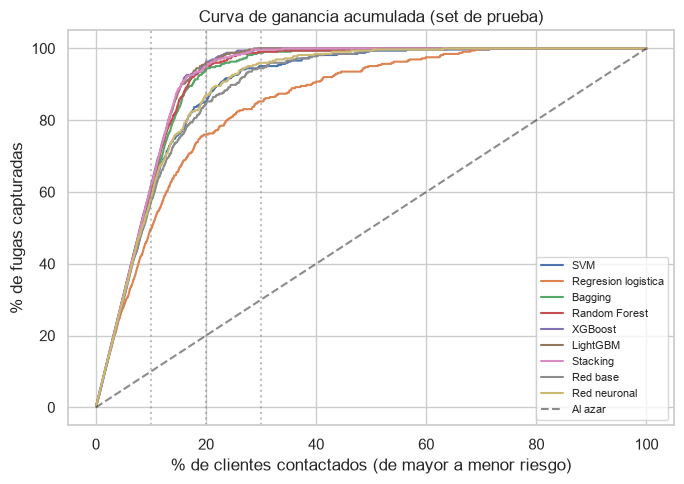

In [31]:
# Miro qué porcentaje de las fugas capturo según el porcentaje de clientes que contacto
ev.plot_ganancia(resultados)

### Análisis: curva de ganancia

- Los cinco ensambles casi se pegan en la curva, así que contactar a los clientes de mayor riesgo funciona igual de bien con cualquiera de ellos.
- El SVM va por debajo entre el 10% y el 40% de clientes contactados. Con el 20% alcanza cerca de 85% de las fugas, contra cerca de 95% de los ensambles.
- La red neuronal también queda por debajo de los ensambles: con el 20% de clientes captura 87,1% de las fugas, contra 95,7% de LightGBM.
- Con LightGBM, contactar al 10% de clientes de mayor riesgo captura 61,8% de las fugas, con el 20% captura 95,7% y con el 30% captura todas.
- Contactar al azar (la línea diagonal) captura solo lo que se contacta: con el 20% de los clientes, solo el 20% de las fugas.
- Para el programa de beneficios no hace falta ofrecerlo a todos. Con el 20% de clientes de mayor riesgo se alcanza casi todo el churn.

## Umbrales de decisión para el programa de beneficios

In [32]:
# Comparo tres umbrales de LightGBM, elegidos con validación cruzada del entrenamiento
utils.cacheado("umbrales_lgbm", lambda: ev.tabla_umbrales(modelos["LightGBM"], datos))

Cargado desde models/cache: umbrales_lgbm


,umbral,clientes_contactados,contactados_%,fugas_detectadas,recall,precision,falsas_alarmas
Máximo F1,0.361,320,15.8,293,0.902,0.916,27
Recall objetivo 80%,0.839,255,12.6,248,0.763,0.973,7
Recall objetivo 90%,0.536,298,14.7,282,0.868,0.946,16


### Análisis: umbrales de decisión

- **Máximo F1 (umbral 0,361):** contacta 320 clientes (15,8%), detecta 293 de las 325 fugas (recall 0,902) y tiene 27 falsas alarmas.
- **Recall objetivo 80% (umbral 0,839):** contacta 255 clientes (12,6%), detecta 248 fugas (recall 0,763) y solo tiene 7 falsas alarmas.
- **Recall objetivo 90% (umbral 0,536):** contacta 298 clientes (14,7%), detecta 282 fugas (recall 0,868) y tiene 16 falsas alarmas.
- Pasar del umbral de 80% al de máximo F1 detecta 45 fugas más, a cambio de contactar 65 clientes más y 20 falsas alarmas más.
- Los umbrales se eligen con validación cruzada del entrenamiento, por eso el recall real en prueba queda un poco por debajo del objetivo (0,763 contra 0,80 y 0,868 contra 0,90).
- Si perder un cliente cuesta más que ofrecer un beneficio de más, conviene el máximo F1. La decisión final depende del costo del beneficio y del valor de cada cliente, que debe definir el banco.

## Indicadores de negocio: metas contra resultados

Las metas son una propuesta para el banco y se pueden cambiar en `METAS` (src/evaluation.py). Se miden en el set de prueba, con el umbral elegido de cada modelo:

- **Recall:** detectar al menos el 85% de las fugas.
- **Precisión:** que al menos 8 de cada 10 clientes contactados se iban a ir.
- **Clientes contactados:** como máximo el 20% de los clientes.
- **Captura con el 20% de mayor riesgo:** alcanzar al menos el 90% de las fugas.
- **PR-AUC:** al menos 0,90.

In [33]:
# Comparo las metas del banco con el resultado de cada modelo en prueba
ev.tabla_indicadores(resultados)

,recall,precision,contactados_%,captura_20%,pr_auc,metas_cumplidas
Meta,>= 0.85,>= 0.8,<= 20,>= 90,>= 0.9,5 de 5
SVM,0.763,0.797,15.4,85.2,0.87,1 de 5
Regresion logistica,0.671,0.701,15.4,76.0,0.737,1 de 5
Bagging,0.883,0.87,16.3,94.2,0.936,5 de 5
Random Forest,0.868,0.887,15.7,95.1,0.953,5 de 5
XGBoost,0.88,0.944,15.0,96.0,0.968,5 de 5
LightGBM,0.902,0.916,15.8,95.7,0.966,5 de 5
Stacking,0.911,0.916,15.9,95.1,0.967,5 de 5
Red base,0.738,0.805,14.7,84.6,0.853,2 de 5
Red neuronal,0.76,0.846,14.4,87.1,0.886,2 de 5


### Análisis: indicadores de negocio

- Bagging, Random Forest, XGBoost, LightGBM y Stacking cumplen las 5 metas.
- LightGBM, el modelo recomendado: recall de 0,902, precisión de 0,916, contacta al 15,8% de los clientes y con el 20% de mayor riesgo alcanza el 95,7% de las fugas.
- El SVM cumple solo 1 de 5 (la precisión queda en 0,797, muy cerca de la meta de 0,80). Las redes cumplen 2 de 5 y la regresión logística, que es el modelo de referencia, solo 1.
- El indicador que más separa a los modelos es el recall: los ensambles detectan entre 0,868 y 0,911 de las fugas y los demás entre 0,671 y 0,763.
- Todos contactan entre el 14% y el 16% de los clientes, por debajo del máximo de 20%, así que esa meta no distingue entre modelos.

## Conclusión

- **Modelo recomendado:** LightGBM, con PR-AUC 0,966, recall 0,902 y F1 0,909 en el set de prueba. Está empatado técnicamente con XGBoost (0,968) y Stacking (0,967), y se elige por simplicidad y rapidez. Es un solo modelo y de los más rápidos de ajustar.
- **Otros modelos:** el SVM (PR-AUC 0,870) y la red neuronal (0,886, empate técnico con el SVM) quedan por debajo de los ensambles (de 0,936 a 0,968). La regresión logística, el modelo de referencia, es el más bajo (0,737).
- **Metas del banco:** los cinco ensambles cumplen las cinco metas propuestas (recall, precisión, clientes contactados, captura con el 20% de clientes y PR-AUC). El SVM, las redes y la regresión logística no.
- **Qué predice el churn:** la actividad del cliente, sobre todo el número y el monto de transacciones, y mucho menos sus datos personales.
- **Para el banco:** con LightGBM, contactar al 10% de clientes de mayor riesgo captura 61,8% de las fugas y al 20% captura 95,7%. No hace falta ofrecer el beneficio a todos.
- **Umbral:** el de máximo F1 detecta 293 de las 325 fugas con 27 falsas alarmas. Si el banco prefiere gastar menos, el umbral de recall 80% contacta menos clientes con solo 7 falsas alarmas. La decisión depende del costo del beneficio y del valor de cada cliente.
- **Limitaciones:** la prueba tiene solo 325 fugas, por eso las diferencias de 0,02 entre los mejores modelos no son confiables. Los datos son de un solo momento y no incluyen el costo real de cada acción del banco.